# 02 — Preprocessing dan Fitur (visualisasi)

Notebook ini memvisualisasikan setiap tahap preprocessing dan cara kerja dua ekstraktor fitur (LBP dan GLCM) pada **satu contoh citra per kelas**. Gambar di sini dipakai untuk laporan dan slide presentasi.

**Status:** visualisasi sudah dikerjakan. Ekstraksi fitur ke seluruh dataset dan cache ke `features/*.csv` **belum dikerjakan** karena menunggu split dari notebook 01.

Contoh citra dipilih acak (seed 42) hanya untuk ilustrasi. Tidak ada statistik agregat di seluruh dataset di notebook ini, supaya data uji tidak ikut "dilihat" sebelum split dibuat.

## Setup environment

Sel ini mendeteksi apakah notebook berjalan di **Google Colab** atau lokal.

Di Colab, Google Drive di-mount dan direktori kerja dipindah ke folder project di Drive. **Sesuaikan `PROJECT_DIR`** dengan lokasi folder project di Drive-mu. Citra hasil ekstraksi ditaruh di disk lokal Colab (`/content/data/raw`) karena membaca ribuan file kecil dari Drive sangat lambat. Akibatnya, citra perlu diekstrak ulang setiap runtime baru (sekitar beberapa detik). `results/` dan `figures/` tetap tersimpan di Drive.

In [1]:
import os
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_DIR = Path("/content/drive/MyDrive/PCD/project")  # <- sesuaikan
    os.environ["BATIK_RAW_DIR"] = "/content/data/raw"  # fast local disk
else:
    PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

assert (PROJECT_DIR / "src" / "project").exists(), f"Folder project tidak ditemukan: {PROJECT_DIR}"
os.chdir(PROJECT_DIR)
sys.path.insert(0, str(PROJECT_DIR / "src"))
print("Colab:", IN_COLAB, "| project:", PROJECT_DIR)

Colab: False | project: C:\Users\ROG\Documents\MKW Semester 7\Pengolahan Citra Digital\project


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from project import config

config.ensure_dirs()
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight"})
rng = np.random.default_rng(config.SEED)

In [3]:
from project.data import build_index, extract_dataset
from project.preprocess import preprocess_stages
from project.features import quantize, glcm_matrices, glcm_props, glcm_features, lbp_map, lbp_features

extract_dataset();  # skipped if already extracted
df = build_index(classes=config.MAIN_CLASSES)
examples = {cls: df[df["label"] == cls].sample(1, random_state=config.SEED)["filepath"].iloc[0]
            for cls in config.MAIN_CLASSES}
stages = {cls: preprocess_stages(fp) for cls, fp in examples.items()}
examples

Dataset already extracted in C:\Users\ROG\Documents\MKW Semester 7\Pengolahan Citra Digital\project\data\raw


{'kawung': 'Kawung/baru_0449,kawung.jpg',
 'megamendung': 'Megamendung/Baru_00069,megamendung.jpg',
 'parang': 'Parang/baru_0193,parang.jpg'}

## 1. Tahap preprocessing: asli → grayscale → CLAHE

- **Grayscale** dengan bobot 0,299R + 0,587G + 0,114B (sama dengan `rgb2gray` MATLAB). GLCM dan LBP bekerja pada intensitas, jadi informasi warna dibuang.
- **CLAHE** (*Contrast Limited Adaptive Histogram Equalization*): citra dibagi 8×8 tile, tiap tile diekualisasi histogramnya sendiri, dan tinggi histogram dibatasi (`clip_limit=0.01`) supaya noise di area datar tidak ikut diperkuat. Hasilnya kontras lokal motif lebih tegas tanpa membuat seluruh citra jenuh. Ini setara `adapthisteq` default MATLAB yang dipakai Fatimah.
- **Tanpa sharpening** — sharpening memperkuat noise frekuensi tinggi, padahal LBP membandingkan piksel dengan tetangga langsungnya sehingga sangat sensitif terhadap noise.
- Ukuran tetap 224×224 (tidak di-resize ke 256) agar tekstur tidak dihaluskan oleh interpolasi.

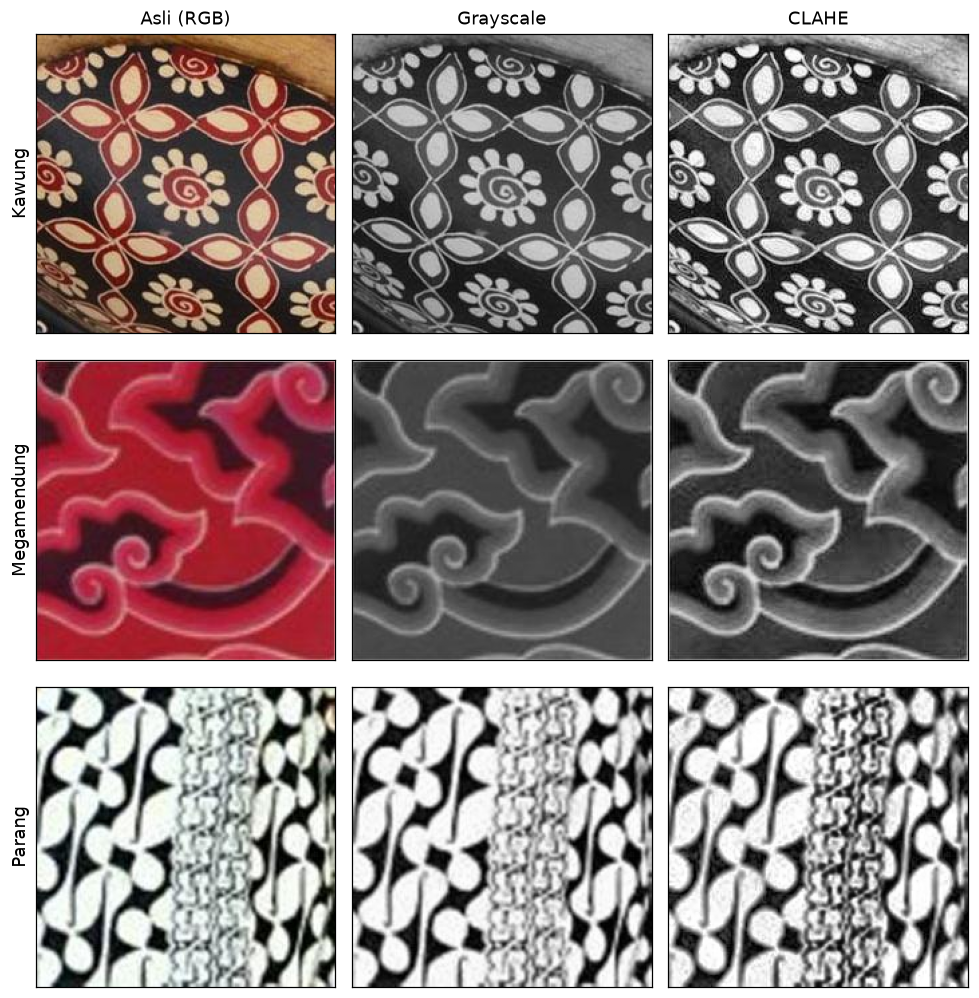

In [4]:
fig, axes = plt.subplots(len(stages), 3, figsize=(9, 3.1 * len(stages)))
titles = ["Asli (RGB)", "Grayscale", "CLAHE"]
for r, (cls, st) in enumerate(stages.items()):
    for c, key in enumerate(["rgb", "gray", "clahe"]):
        ax = axes[r, c]
        ax.imshow(st[key], cmap=None if key == "rgb" else "gray", vmin=0, vmax=255)
        ax.set_xticks([]); ax.set_yticks([])
        if r == 0:
            ax.set_title(titles[c])
        if c == 0:
            ax.set_ylabel(cls.capitalize(), fontsize=12)
fig.tight_layout()
fig.savefig(config.FIGURES_DIR / "02_tahap_preprocessing.png")
plt.show()

Efek CLAHE lebih mudah dilihat di histogram: distribusi intensitas grayscale biasanya menumpuk di rentang sempit, sedangkan setelah CLAHE menyebar ke rentang yang lebih lebar.

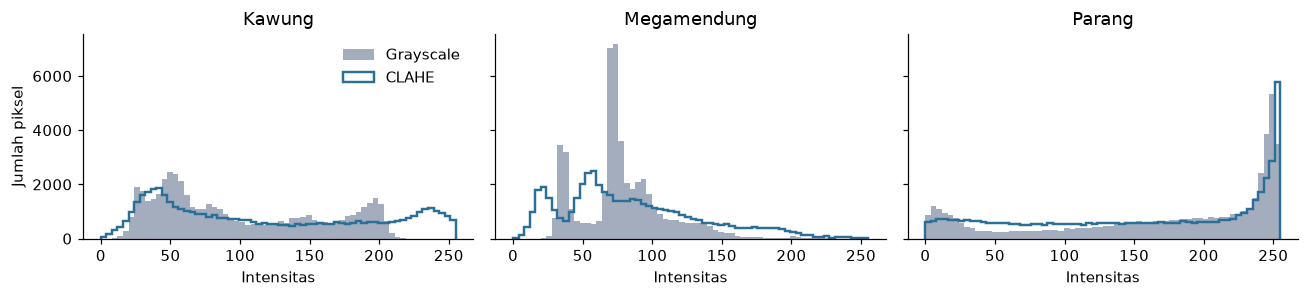

In [5]:
fig, axes = plt.subplots(1, len(stages), figsize=(4 * len(stages), 2.8), sharey=True)
for ax, (cls, st) in zip(axes, stages.items()):
    ax.hist(st["gray"].ravel(), bins=64, range=(0, 255), color="#8d99ae", alpha=0.8, label="Grayscale")
    ax.hist(st["clahe"].ravel(), bins=64, range=(0, 255), histtype="step", color="#2a6f97", lw=1.6, label="CLAHE")
    ax.set_title(cls.capitalize())
    ax.set_xlabel("Intensitas")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Jumlah piksel")
axes[0].legend(frameon=False)
fig.tight_layout()
fig.savefig(config.FIGURES_DIR / "02_histogram_clahe.png")
plt.show()

## 2. Local Binary Pattern (LBP)

Untuk tiap piksel, 8 tetangga pada radius 1 dibandingkan dengan piksel pusat: tetangga ≥ pusat diberi bit 1, sisanya 0, menghasilkan kode 8-bit. Pola **uniform** adalah kode dengan paling banyak 2 transisi 0↔1 secara melingkar (misalnya `00011100`); pola ini mewakili tepi, sudut, dan titik. Varian `nri_uniform` (*non-rotation-invariant*) memberi label sendiri ke tiap pola uniform (58 label) dan menggabungkan semua pola non-uniform ke satu label → **59 bin**. Fitur akhir adalah histogram 59 bin yang dinormalisasi L2.

Peta LBP di bawah menampilkan kode per piksel; warna yang sama berarti pola lokal yang sama.

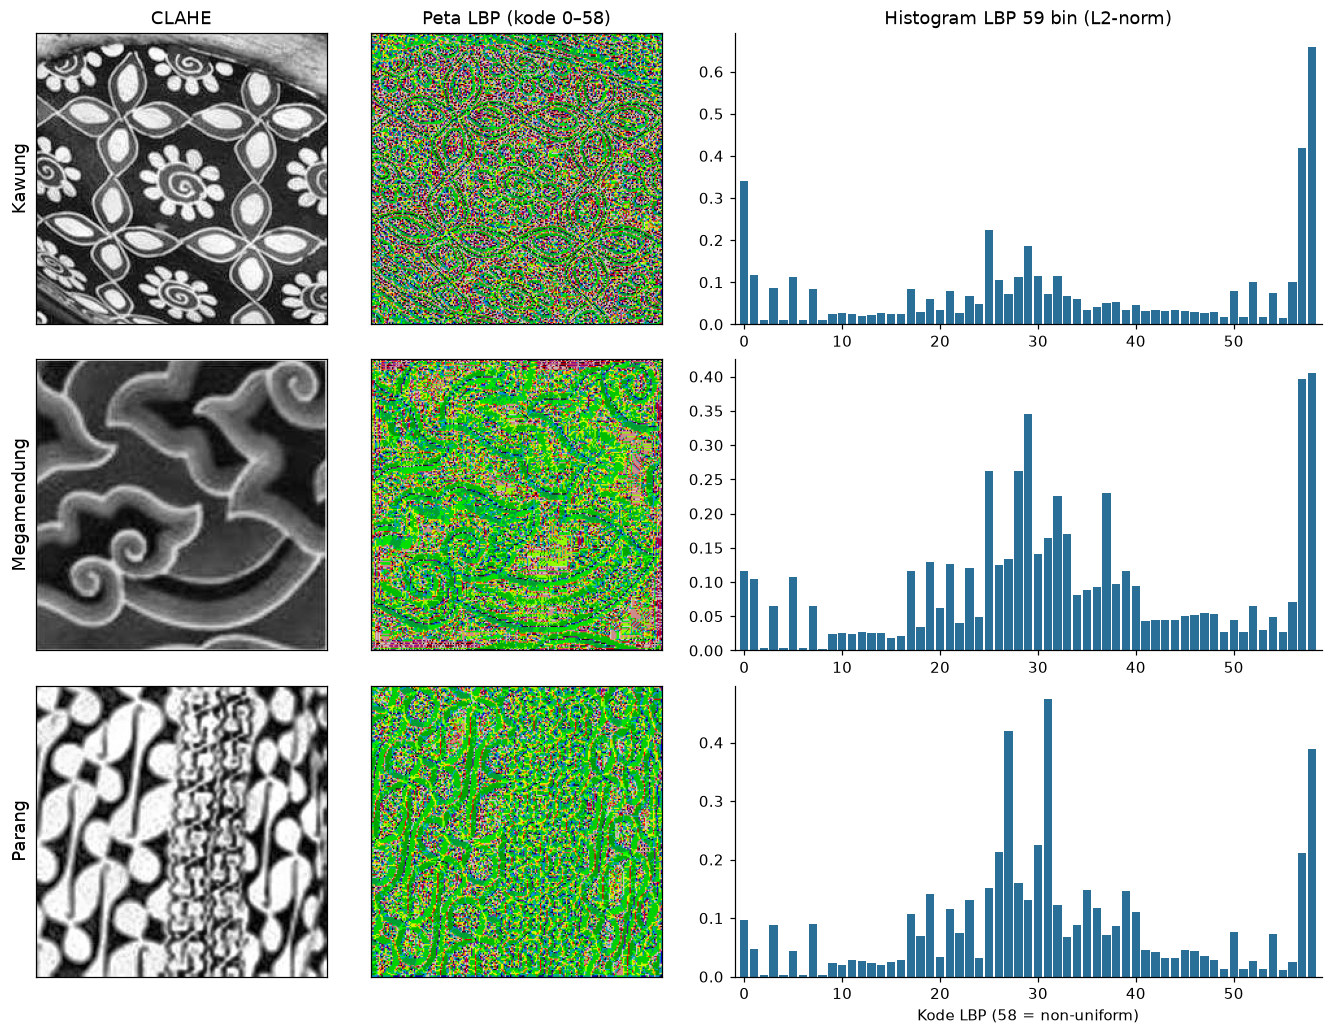

In [6]:
fig, axes = plt.subplots(len(stages), 3, figsize=(12, 3.1 * len(stages)),
                         gridspec_kw={"width_ratios": [1, 1, 1.8]}, layout="constrained")
for r, (cls, st) in enumerate(stages.items()):
    codes = lbp_map(st["clahe"])
    hist = np.array(list(lbp_features(st["clahe"]).values()))
    axes[r, 0].imshow(st["clahe"], cmap="gray"); axes[r, 0].set_ylabel(cls.capitalize(), fontsize=12)
    axes[r, 1].imshow(codes, cmap="nipy_spectral", vmin=0, vmax=58)
    axes[r, 2].bar(np.arange(59), hist, color="#2a6f97", width=0.85)
    axes[r, 2].set_xlim(-1, 59)
    axes[r, 2].spines[["top", "right"]].set_visible(False)
    for ax in axes[r, :2]:
        ax.set_xticks([]); ax.set_yticks([])
    if r == 0:
        axes[r, 0].set_title("CLAHE"); axes[r, 1].set_title("Peta LBP (kode 0–58)")
        axes[r, 2].set_title("Histogram LBP 59 bin (L2-norm)")
axes[-1, 2].set_xlabel("Kode LBP (58 = non-uniform)")
fig.savefig(config.FIGURES_DIR / "02_peta_lbp.png")
plt.show()

## 3. Gray Level Co-occurrence Matrix (GLCM)

GLCM menghitung seberapa sering pasangan intensitas (i, j) muncul pada dua piksel yang terpisah jarak *d* dengan arah θ. Sebelum dihitung, citra dikuantisasi ke **8 level** (default `graycomatrix` MATLAB yang dipakai Andono) sehingga matriksnya 8×8 dan tidak terlalu jarang.

Dari GLCM dihitung 4 properti:
- **Kontras** Σ(i−j)²P(i,j) — besar jika banyak pasangan piksel berbeda jauh.
- **Korelasi** — keteraturan linear hubungan intensitas antar-pasangan.
- **Energi (ASM)** ΣP(i,j)² — besar jika tekstur seragam/berulang.
- **Homogenitas** ΣP(i,j)/(1+|i−j|) — besar jika massa GLCM terkumpul di diagonal. Rumus ini mengikuti paper dan MATLAB; versi `skimage` memakai (i−j)², jadi dihitung manual.

Pertama, citra hasil kuantisasi 8 level:

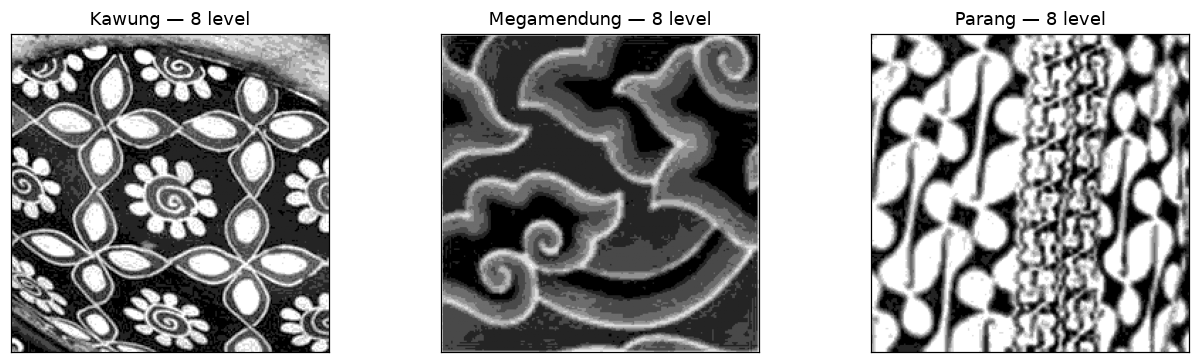

In [7]:
fig, axes = plt.subplots(1, len(stages), figsize=(4 * len(stages), 3.4))
for ax, (cls, st) in zip(axes, stages.items()):
    ax.imshow(quantize(st["clahe"]), cmap="gray", vmin=0, vmax=config.GLCM_LEVELS - 1)
    ax.set_title(f"{cls.capitalize()} — {config.GLCM_LEVELS} level")
    ax.set_xticks([]); ax.set_yticks([])
fig.tight_layout()
plt.show()

### GLCM di 4 arah (d = 1)

Pertanyaan RM3 adalah apakah memakai 4 arah lebih baik daripada 0° saja. Heatmap di bawah menunjukkan GLCM satu citra di keempat arah. Jika tekstur punya orientasi dominan (misalnya motif diagonal Parang), GLCM di arah yang searah motif akan lebih terkonsentrasi di diagonal (kontras kecil), sedangkan arah yang memotong motif akan lebih menyebar (kontras besar).

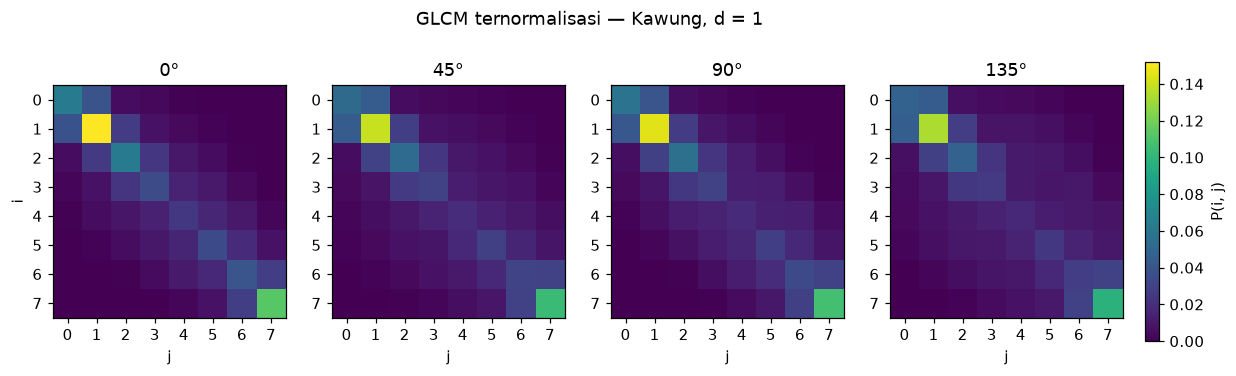

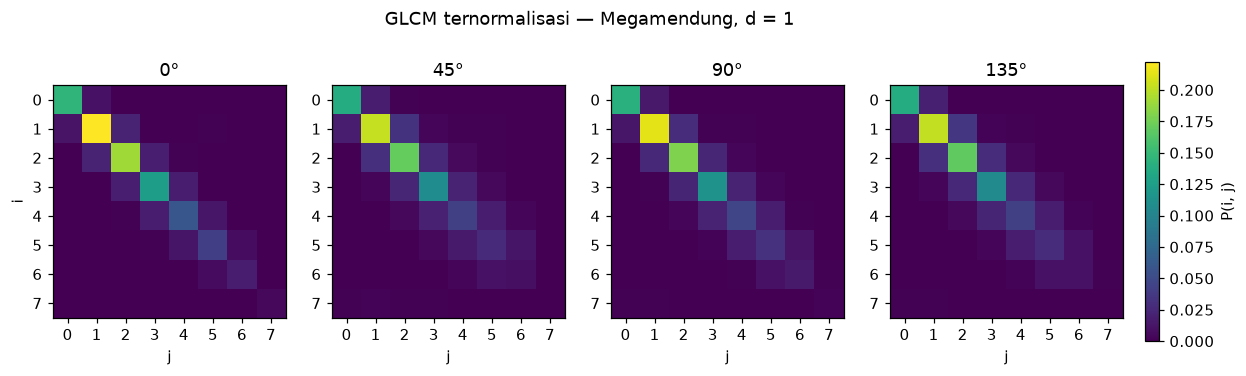

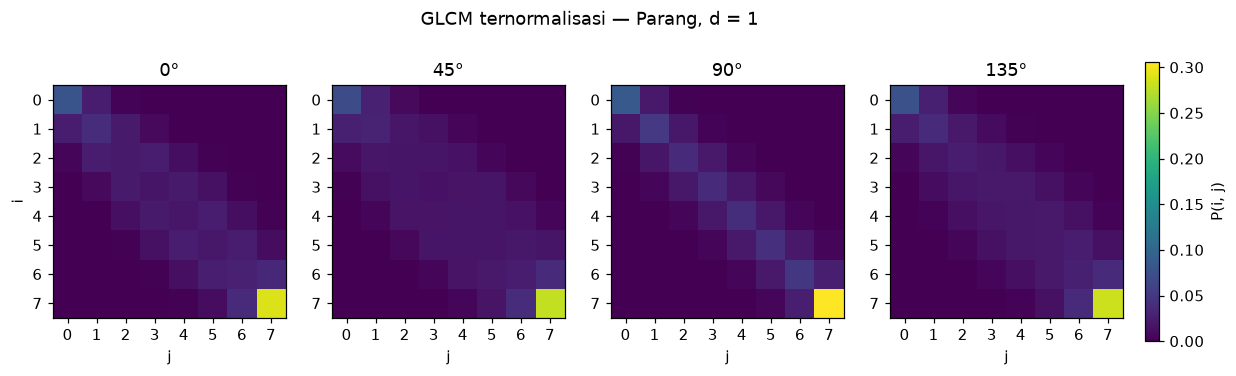

In [8]:
angle_labels = ["0°", "45°", "90°", "135°"]

def plot_glcm_4dir(cls, d_index=0):
    P = glcm_matrices(stages[cls]["clahe"])
    fig, axes = plt.subplots(1, 4, figsize=(13, 3.3))
    vmax = P[:, :, d_index, :].max()
    for k, ax in enumerate(axes):
        im = ax.imshow(P[:, :, d_index, k], cmap="viridis", vmin=0, vmax=vmax)
        ax.set_title(f"{angle_labels[k]}")
        ax.set_xlabel("j"); ax.set_ylabel("i" if k == 0 else "")
        ax.set_xticks(range(config.GLCM_LEVELS)); ax.set_yticks(range(config.GLCM_LEVELS))
    fig.colorbar(im, ax=axes, fraction=0.015, pad=0.02, label="P(i, j)")
    fig.suptitle(f"GLCM ternormalisasi — {cls.capitalize()}, d = {config.GLCM_DISTANCES[d_index]}", y=1.02)
    return fig

for cls in config.MAIN_CLASSES:
    fig = plot_glcm_4dir(cls)
    fig.savefig(config.FIGURES_DIR / f"02_glcm_{cls}.png")
    plt.show()

### Nilai properti GLCM per arah dan jarak

Tabel berikut adalah nilai keempat properti untuk satu contoh citra per kelas. Perhatikan seberapa besar nilai di sudut 0° berbeda dari rata-rata 4 arah — selisih ini adalah informasi yang hilang di skenario S1. Ini **ilustrasi satu citra**, bukan bukti untuk hipotesis.

In [9]:
rows = []
for cls, st in stages.items():
    props = glcm_props(glcm_matrices(st["clahe"]))
    for name in config.GLCM_PROPS:
        for di, d in enumerate(config.GLCM_DISTANCES):
            row = {"kelas": cls, "properti": name, "d": d}
            row.update({lab: props[name][di, k] for k, lab in enumerate(angle_labels)})
            row["rata-rata 4 arah"] = props[name][di].mean()
            rows.append(row)
glcm_table = pd.DataFrame(rows).set_index(["kelas", "properti", "d"])
glcm_table.round(3)

0°    45°    90°   135°  rata-rata 4 arah
kelas       properti    d                                              
kawung      contrast    1  1.211  1.920  1.501  2.456             1.772
                        3  4.560  4.178  5.452  5.071             4.815
                        5  6.514  6.834  7.327  7.655             7.083
            correlation 1  0.895  0.833  0.870  0.787             0.846
                        3  0.605  0.638  0.527  0.560             0.583
                        5  0.436  0.409  0.366  0.338             0.387
            asm         1  0.058  0.050  0.053  0.046             0.052
                        3  0.038  0.040  0.035  0.036             0.037
                        5  0.031  0.030  0.028  0.027             0.029
            homogeneity 1  0.733  0.687  0.701  0.657             0.694
                        3  0.606  0.615  0.574  0.589             0.596
                        5  0.545  0.532  0.516  0.506             0.525
megamendung contrast    1  0.374  0.757  0.468  0.719             0.580
                        3  0.970  1.368  1.460  1.249             1.262
                        5  1.685  2.609  2.545  2.482             2.330
            correlation 1  0.927  0.849  0.909  0.857             0.886
                        3  0.812  0.728  0.716  0.751             0.752
                        5  0.673  0.480  0.505  0.505             0.541
            asm         1  0.131  0.109  0.119  0.109             0.117
                        3  0.092  0.086  0.078  0.086             0.086
                        5  0.075  0.063  0.062  0.064             0.066
            homogeneity 1  0.900  0.837  0.867  0.839             0.861
                        3  0.794  0.767  0.741  0.767             0.767
                        5  0.731  0.674  0.667  0.672             0.686
parang      contrast    1  0.953  1.487  0.543  1.163             1.037
                        3  5.327  4.448  3.010  3.419             4.051
                        5  9.016  9.660  5.790  7.787             8.063
            correlation 1  0.926  0.884  0.958  0.910             0.919
                        3  0.586  0.654  0.766  0.734             0.685
                        5  0.299  0.248  0.549  0.394             0.373
            asm         1  0.105  0.095  0.119  0.100             0.105
                        3  0.061  0.068  0.081  0.074             0.071
                        5  0.042  0.042  0.063  0.048             0.049
            homogeneity 1  0.733  0.692  0.816  0.724             0.741
                        3  0.547  0.577  0.654  0.612             0.598
                        5  0.472  0.472  0.579  0.506             0.507

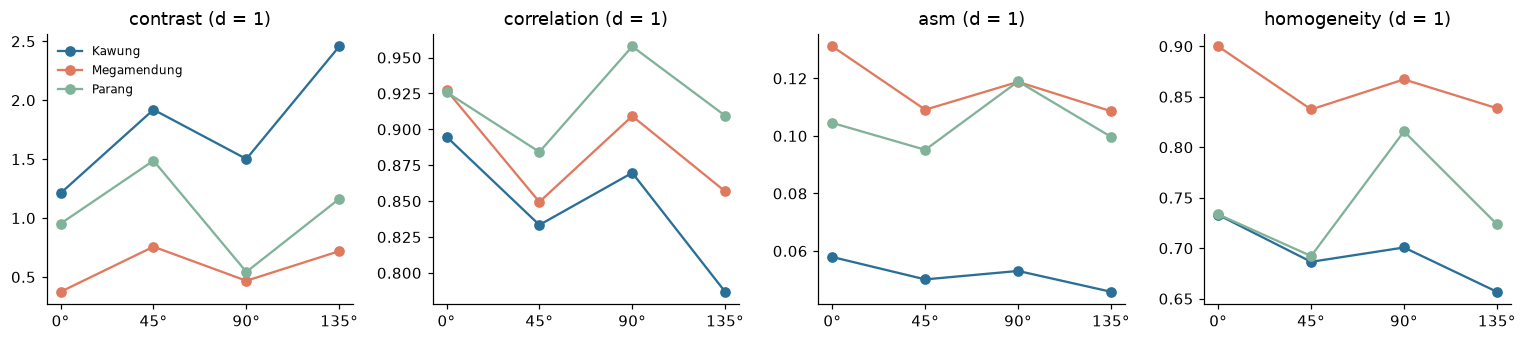

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.2))
for ax, name in zip(axes, config.GLCM_PROPS):
    for cls, color in zip(config.MAIN_CLASSES, ["#2a6f97", "#e07a5f", "#81b29a"]):
        vals = glcm_table.loc[(cls, name, 1), angle_labels].values
        ax.plot(angle_labels, vals, marker="o", color=color, label=cls.capitalize())
    ax.set_title(f"{name} (d = 1)")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(config.FIGURES_DIR / "02_glcm_per_arah.png")
plt.show()

### Vektor fitur per skenario (satu citra)

Pengecekan dimensi vektor fitur sesuai tabel skenario: S1 = 12, S2 = 12, S3 = 59, S4 = 71.

In [11]:
gray = stages["parang"]["clahe"]
s1 = glcm_features(gray, mode="0deg")
s2 = glcm_features(gray, mode="4dir")
s3 = lbp_features(gray)
s4 = {**s2, **s3}
pd.DataFrame({"skenario": ["S1", "S2", "S3", "S4"],
              "dimensi": [len(s1), len(s2), len(s3), len(s4)],
              "contoh kolom": [list(s1)[0], list(s2)[0], list(s3)[0], f"{list(s4)[0]} … {list(s4)[-1]}"]})

,skenario,dimensi,contoh kolom
0,S1,12,glcm_contrast_d1_a0
1,S2,12,glcm_contrast_d1_mean
2,S3,59,lbp_00
3,S4,71,glcm_contrast_d1_mean … lbp_58


## 4. Ekstraksi fitur seluruh dataset — *belum dikerjakan*

> **Placeholder.** Menunggu `results/split.csv` dari notebook 01. Rencana: hitung S1–S4 untuk semua citra 3 kelas utama, simpan ke `features/*.csv` dengan kolom `filename, label, group_id, split, fitur...`.